In [3]:
!pip install transformers pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 1.6 MB/s  0:00:07m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 796.8/796.8 kB 1.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 1.7 MB/s  0:00:03 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 1.8 MB/s  0:00:01 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13/13 [transformers] [transformers]ub]


## Environment Setup & Model Initialization

In [4]:
import os
import time
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import AutoImageProcessor, AutoModelForDepthEstimation
from ultralytics import YOLO

# Hardware device configuration (Apple Silicon MPS Acceleration)
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using compute acceleration device: {device}")

# Define relative paths based on your repository layout
PROJECT_ROOT = os.path.abspath("..")
IMAGE_DIR = os.path.join(PROJECT_ROOT, "v1.0-mini", "samples", "CAM_FRONT")
OUTPUT_DIR = os.path.join(PROJECT_ROOT, "outputs", "fusion_results")
EXCEL_PATH = os.path.join(PROJECT_ROOT, "notebooks", "experiment_results.xlsx")

os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Load Instance Segmentation Model (YOLOv11-Nano)
seg_model = YOLO("yolo11n-seg.pt")

# 2. Load Depth Anything V2 Small Model via Hugging Face Transformers
depth_encoder_model = "depth-anything/Depth-Anything-V2-Small-hf"
depth_processor = AutoImageProcessor.from_pretrained(depth_encoder_model)
depth_model = AutoModelForDepthEstimation.from_pretrained(
    depth_encoder_model
).to(device)

# Risk Severity Class Weights ($W_{class}$)
CLASS_WEIGHTS = {
    0: 1.00,  # Person / Pedestrian (Highest)
    1: 0.85,  # Bicycle
    2: 0.55,  # Car
    3: 0.85,  # Motorcycle
    5: 0.70,  # Bus
    7: 0.70,  # Truck
    11: 0.30,  # Stop Sign / Barrier (Static Hazard)
}
DEFAULT_STATIC_WEIGHT = 0.20

/opt/anaconda3/envs/av_risk/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using compute acceleration device: mps


Loading weights: 100%|██████████| 287/287 [00:00<00:00, 15676.07it/s]


## Feature Fusion Pipeline Implementation

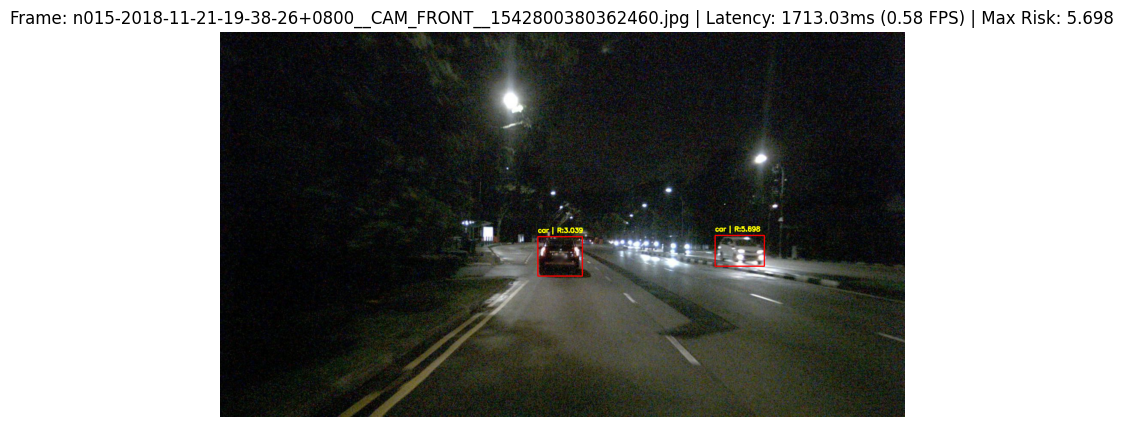

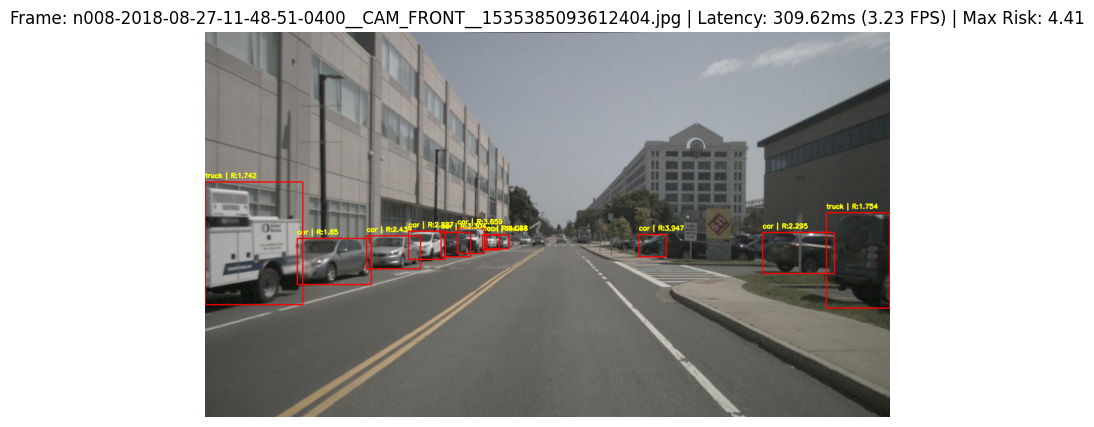

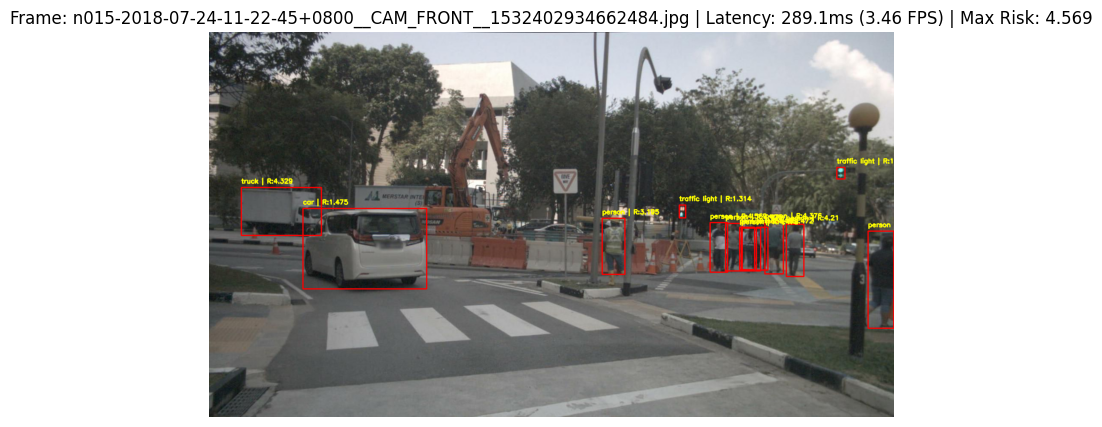

In [5]:
# Select test images from v1.0-mini CAM_FRONT
sample_images = [
    f
    for f in os.listdir(IMAGE_DIR)
    if f.endswith(".jpg") or f.endswith(".png")
][:3]

fusion_records = []

for img_file in sample_images:
    img_path = os.path.join(IMAGE_DIR, img_file)
    raw_img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB)
    h, w, _ = raw_img.shape

    start_time = time.time()

    # Step 1: Run YOLO Segmentation Inference
    seg_results = seg_model.predict(
        source=img_path, device=device, verbose=False
    )[0]

    # Step 2: Run Depth Anything V2 Depth Estimation Inference
    inputs = depth_processor(images=img_rgb, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = depth_model(**inputs)
        predicted_depth = outputs.predicted_depth

    # Interpolate depth map back to original input image resolution
    depth_map = torch.nn.functional.interpolate(
        predicted_depth.unsqueeze(1),
        size=(h, w),
        mode="bicubic",
        align_corners=False,
    ).squeeze().cpu().numpy()

    # Normalize depth map for relative proximity inversion (1 / depth)
    depth_normalized = (depth_map - depth_map.min()) / (
        depth_map.max() - depth_map.min() + 1e-6
    )

    # Step 3: Mask-Guided Depth Fusion & Weighted Risk Index Engine
    annotated_img = img_rgb.copy()
    max_frame_risk = 0.0
    detected_objects = []

    if seg_results.masks is not None and seg_results.boxes is not None:
        masks = seg_results.masks.data.cpu().numpy()
        boxes = seg_results.boxes

        for idx, mask in enumerate(masks):
            cls_id = int(boxes.cls[idx].item())
            conf = float(boxes.conf[idx].item())
            class_name = seg_model.names[cls_id]

            # Resize binary mask array to raw image resolution
            binary_mask = cv2.resize(mask, (w, h)) > 0.5

            # Mask-Guided Depth Extraction: Compute median relative depth
            if np.sum(binary_mask) > 0:
                object_depth = np.median(depth_normalized[binary_mask])
            else:
                object_depth = 0.0

            # Compute Inverse Proximity Distance Hazard (1 / depth)
            proximity_score = 1.0 / (object_depth + 1e-3)

            # Assign Class Risk Weight $W_{class}$
            w_class = CLASS_WEIGHTS.get(cls_id, DEFAULT_STATIC_WEIGHT)

            # Compute Object Risk Score
            risk_score = round(float(w_class * proximity_score), 3)

            if risk_score > max_frame_risk:
                max_frame_risk = risk_score

            detected_objects.append({
                "class": class_name,
                "weight": w_class,
                "depth_rel": round(float(object_depth), 3),
                "risk": risk_score,
            })

            # Draw visual bounding boxes and overlay risk score on image
            box = boxes.xyxy[idx].cpu().numpy().astype(int)
            cv2.rectangle(
                annotated_img,
                (box[0], box[1]),
                (box[2], box[3]),
                (255, 0, 0),
                2,
            )
            cv2.putText(
                annotated_img,
                f"{class_name} | R:{risk_score}",
                (box[0], max(box[1] - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (255, 255, 0),
                2,
            )

    latency_ms = round((time.time() - start_time) * 1000, 2)
    fps = round(1000 / latency_ms, 2)

    # Display annotated prediction output
    plt.figure(figsize=(10, 5))
    plt.imshow(annotated_img)
    plt.title(
        f"Frame: {img_file} | Latency: {latency_ms}ms ({fps} FPS) | Max Risk: {max_frame_risk}"
    )
    plt.axis("off")
    plt.show()

    # Save visualization to outputs folder
    save_path = os.path.join(OUTPUT_DIR, f"approach_a_{img_file}")
    cv2.imwrite(save_path, cv2.cvtColor(annotated_img, cv2.COLOR_RGB2BGR))

    # Save metrics record
    fusion_records.append({
        "Exp_ID": f"EXP_FUSION_A_{int(time.time())}",
        "Timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
        "Task": "Approach A - Early/Late Parallel Fusion",
        "Segmentation_Model": "YOLOv11-Nano",
        "Depth_Model": "Depth-Anything-V2-Small",
        "Sample_Image": img_file,
        "Total_Objects": len(detected_objects),
        "Max_Risk_Score": max_frame_risk,
        "Latency_ms": latency_ms,
        "FPS": fps,
        "Device": str(device),
    })

## Log Results into Excel Tracker

In [6]:
# Save results to central Excel tracker
df_fusion = pd.DataFrame(fusion_records)

if os.path.exists(EXCEL_PATH):
    df_existing = pd.read_excel(EXCEL_PATH)
    df_final = pd.concat([df_existing, df_fusion], ignore_index=True)
else:
    df_final = df_fusion

df_final.to_excel(EXCEL_PATH, index=False)
print(f"Logged Approach A results to {EXCEL_PATH}")

df_fusion[
    [
        "Sample_Image",
        "Total_Objects",
        "Max_Risk_Score",
        "Latency_ms",
        "FPS",
        "Device",
    ]
]

Logged Approach A results to /Users/anupamahalder/Autonomous_Vehicle_Risk_Estimation_Analysis/notebooks/experiment_results.xlsx


,Sample_Image,Total_Objects,Max_Risk_Score,Latency_ms,FPS,Device
0,n015-2018-11-21-19-38-26+0800__CAM_FRONT__1542...,2,5.698,1713.03,0.58,mps
1,n008-2018-08-27-11-48-51-0400__CAM_FRONT__1535...,11,4.410,309.62,3.23,mps
2,n015-2018-07-24-11-22-45+0800__CAM_FRONT__1532...,13,4.569,289.10,3.46,mps
